In [1]:
%pip install cryptography
import os
import random
import time
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
from cryptography.hazmat.backends import default_backend

# Fixed seed so the packet-loss simulations give the same numbers on every run
SEED = 42
random.seed(SEED)


Note: you may need to restart the kernel to use updated packages.


In [2]:
from IPython.display import display, clear_output
import pandas as pd

simulation_results = {
    "ACR Auth (10% Packet Loss)": {"Before": "❌ 12% Failure", "After": "Not Run Yet"},
    "ACR + Retry (3 attempts)": {"Before": "—", "After": "Not Run Yet"},
    "APCE Auth (250ms Latency)": {"Before": "🕒 Full RSA + ECDHE Latency", "After": "Not Run Yet"},
    "Truncated MAC (8 bytes)": {"Before": "❌ MAC overflow risk", "After": "Not Run Yet"},
    "Agent Mode (RSA Signature)": {"Before": "Not Simulated", "After": "Not Run Yet"},
    "Key Rotation (every 3 sessions)": {"Before": "❌ No lifecycle", "After": "Not Run Yet"},
    "ACR Realistic Loss Model": {"Before": "⚠️ Simulated Loss: 10%", "After": "Not Run Yet"}
}

# Measured failure rates (%), filled in by the simulations below
failure_rates = {}

In [3]:
import hmac
import hashlib

# Shared secret key between Tester and SECU (in real SAFUA, managed by Key Management Center)
shared_secret_key = b'safua_shared_key_128bit'

def acr_authenticate(message: str, received_message: str = None, key: bytes = None):
    """
    Simulates ACR authentication (HMAC-SHA256) between Tester and SECU.
    received_message is what arrives at SECU; it defaults to the message the
    Tester sent and differs when the data was corrupted in transit.
    """
    key = key or shared_secret_key
    if received_message is None:
        received_message = message

    # Step 1: Tester creates HMAC over the message it sends
    mac = hmac.new(key, message.encode(), hashlib.sha256).digest()

    # Step 2: SECU recomputes the HMAC over the message it received
    expected_mac = hmac.new(key, received_message.encode(), hashlib.sha256).digest()

    # Step 3: Constant-time comparison
    if hmac.compare_digest(mac, expected_mac):
        return "✅ ACR Authentication Successful"
    else:
        return "❌ ACR Authentication Failed"


print(acr_authenticate("Firmware Update v1.2"))
print(acr_authenticate("Firmware Update v1.2", received_message="Firmware Update v6.6"))


✅ ACR Authentication Successful
❌ ACR Authentication Failed


In [4]:
from cryptography.hazmat.primitives.asymmetric import rsa, ec
from cryptography.hazmat.primitives.asymmetric import padding
from cryptography.hazmat.primitives import serialization

# Step 1: Generate RSA key pair (Tester)
tester_private_key = rsa.generate_private_key(public_exponent=65537, key_size=2048)
tester_public_key = tester_private_key.public_key()

# Step 2: Generate ECDHE key pair (both sides)
tester_ecdh = ec.generate_private_key(ec.SECP384R1())
secu_ecdh = ec.generate_private_key(ec.SECP384R1())

# Step 3: Exchange public keys and derive shared secret
shared_key_tester = tester_ecdh.exchange(ec.ECDH(), secu_ecdh.public_key())
shared_key_secu = secu_ecdh.exchange(ec.ECDH(), tester_ecdh.public_key())

# Step 4: Derive AES key from shared ECDHE secret
derived_key = HKDF(
    algorithm=hashes.SHA256(),
    length=16,
    salt=None,
    info=b'safua key derivation',
    backend=default_backend()
).derive(shared_key_tester)

# Step 5: Encrypt with AES128 (GCM mode for simplicity)
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

aesgcm = AESGCM(derived_key)
nonce = os.urandom(12)
plaintext = b"APCE Firmware Update v2.0"
ciphertext = aesgcm.encrypt(nonce, plaintext, None)

# Step 6: Decrypt (simulate SECU)
decrypted = aesgcm.decrypt(nonce, ciphertext, None)

print("✅ APCE Authentication Successful")
print("🔒 Encrypted:", ciphertext)
print("🔓 Decrypted:", decrypted.decode())


✅ APCE Authentication Successful
🔒 Encrypted: b'\x95\x9d\x98\xca\xaaWu\x7f\x01\x0c:P\xfe\x1f\x92\x80|\x96\xd2\xf0llw+\x10Hb\xb9\xb2\xef\xc4v\x8a\xddI\x05\x0e\x88\x9f\xd9\x0f'
🔓 Decrypted: APCE Firmware Update v2.0


In [5]:
from cryptography.hazmat.primitives.asymmetric import utils
from cryptography.exceptions import InvalidSignature

# Step 1: GECU generates key pair (acts like CA/certificate authority)
gecu_private_key = rsa.generate_private_key(public_exponent=65537, key_size=2048)
gecu_public_key = gecu_private_key.public_key()

# Step 2: GECU signs firmware payload
firmware_data = b"Agent Mode Firmware Patch v3.1"
signature = gecu_private_key.sign(
    firmware_data,
    padding.PSS(mgf=padding.MGF1(hashes.SHA256()), salt_length=padding.PSS.MAX_LENGTH),
    hashes.SHA256()
)

# Step 3: Tester verifies signature before sending to SECU
try:
    gecu_public_key.verify(
        signature,
        firmware_data,
        padding.PSS(mgf=padding.MGF1(hashes.SHA256()), salt_length=padding.PSS.MAX_LENGTH),
        hashes.SHA256()
    )

    simulation_results["Agent Mode (RSA Signature)"]["After"] = "✅ Verified Signature"
    print("✅ Agent Mode Authentication Successful")
    print("📩 Firmware ready to be sent to SECU")
except InvalidSignature:
    print("❌ Agent Mode Verification Failed")


✅ Agent Mode Authentication Successful
📩 Firmware ready to be sent to SECU


In [6]:
import time

def acr_with_packet_loss_simulation(trials=100, loss_rate=0.10):
    failed = 0
    for i in range(trials):
        if random.random() < loss_rate:
            result = acr_authenticate("Firmware Update v1.2", received_message="Corrupted Data")
        else:
            result = acr_authenticate("Firmware Update v1.2")

        if "Failed" in result:
            failed += 1

    success = trials - failed

    simulation_results["ACR Auth (10% Packet Loss)"]["After"] = f"✅ Success: {success} | ❌ Failures: {failed} | ⚠️ {failed/trials*100:.2f}%"
    print(f"📊 ACR Simulation (with {int(loss_rate*100)}% packet loss over {trials} runs):")
    print(f"✅ Success: {success}")
    print(f"❌ Failures: {failed}")
    print(f"⚠️ Failure Rate: {failed/trials*100:.2f}%")


start_time = time.time()
acr_with_packet_loss_simulation()
end_time = time.time()
print(f"\n⏱️ Execution Time: {end_time - start_time:.4f} seconds")

📊 ACR Simulation (with 10% packet loss over 100 runs):
✅ Success: 87
❌ Failures: 13
⚠️ Failure Rate: 13.00%

⏱️ Execution Time: 0.0009 seconds


In [7]:
import time
import random

def acr_with_packet_loss_realistic(trials=100, loss_rate=0.10):
    failed = 0
    for i in range(trials):
        if random.random() < loss_rate:
            failed += 1
        else:
            result = acr_authenticate("Firmware Update v1.2")
            if "Failed" in result:
                failed += 1

    success = trials - failed
    failure_rates["No Retry"] = failed / trials * 100

    print(f"📊 Realistic ACR Simulation (with {int(loss_rate*100)}% packet loss over {trials} runs):")

    simulation_results["ACR Realistic Loss Model"]["After"] = (
        f"✅ Success: {success} | ❌ Failures: {failed} | 📊 Failure Rate: {failed/trials*100:.2f}%"
    )

    print(f"✅ Success: {success}")
    print(f"❌ Failures: {failed}")
    print(f"⚠️ Failure Rate: {failed/trials*100:.2f}%")

start_time = time.time()
acr_with_packet_loss_realistic()
end_time = time.time()
print(f"\n⏱️ Execution Time: {end_time - start_time:.4f} seconds")


📊 Realistic ACR Simulation (with 10% packet loss over 100 runs):
✅ Success: 89
❌ Failures: 11
⚠️ Failure Rate: 11.00%

⏱️ Execution Time: 0.0008 seconds


In [8]:
import time

def simulate_apce_with_latency(latency_ms=250):
    start = time.time()

    shared_key = HKDF(
        algorithm=hashes.SHA256(),
        length=16,
        salt=None,
        info=b'safua key derivation',
        backend=default_backend()
    ).derive(shared_key_tester)

    aesgcm = AESGCM(shared_key)
    nonce = os.urandom(12)
    firmware = b"Critical Firmware v2.3"


    time.sleep(latency_ms / 1000)

    ciphertext = aesgcm.encrypt(nonce, firmware, None)
    decrypted = aesgcm.decrypt(nonce, ciphertext, None)

    end = time.time()
    duration_ms = (end - start) * 1000

    simulation_results["APCE Auth (250ms Latency)"]["After"] = f"✅ {duration_ms:.2f}ms Measured Delay"
    print(f"🕒 Total APCE Roundtrip Time (with {latency_ms}ms simulated delay): {duration_ms:.2f}ms")
    print("🔓 Decrypted:", decrypted.decode())

simulate_apce_with_latency()


🕒 Total APCE Roundtrip Time (with 250ms simulated delay): 250.43ms
🔓 Decrypted: Critical Firmware v2.3


In [9]:
def simulate_concurrent_ecu_updates(ecu_count=5, packet_loss=0.1):
    results = []
    print("🚗 Starting concurrent firmware updates to 5 ECUs...")

    for ecu in range(ecu_count):
        if random.random() < packet_loss:
            results.append(f"ECU {ecu+1}: ❌ Packet Lost (Update Failed)")
        else:
            auth_result = acr_authenticate("Concurrent Firmware Update v4.0")
            results.append(f"ECU {ecu+1}: {auth_result}")

    print("\n📊 Update Results:")
    for r in results:
        print(r)

simulate_concurrent_ecu_updates()


🚗 Starting concurrent firmware updates to 5 ECUs...

📊 Update Results:
ECU 1: ✅ ACR Authentication Successful
ECU 2: ✅ ACR Authentication Successful
ECU 3: ✅ ACR Authentication Successful
ECU 4: ✅ ACR Authentication Successful
ECU 5: ✅ ACR Authentication Successful


In [10]:
import time

def acr_with_retry_simulation(trials=100, loss_rate=0.10, max_retries=3):
    recovered = 0
    failed = 0

    for _ in range(trials):
        for attempt in range(max_retries):
            if random.random() < loss_rate:
                continue
            result = acr_authenticate("Resilient Firmware Update v5.0")
            if "Successful" in result:
                recovered += 1
                break
        else:
            failed += 1

    failure_rates["With Retry"] = failed / trials * 100
    print(f"📈 Retry-on-Loss Simulation ({trials} sessions with {int(loss_rate*100)}% loss):")

    simulation_results["ACR + Retry (3 attempts)"]["After"] = f"✅ Recovered: {recovered} | ❌ Failed: {failed} | 📊 {failed/trials*100:.2f}%"
    print(f"✅ Recovered via retry: {recovered}")
    print(f"❌ Still Failed after {max_retries} attempts: {failed}")
    print(f"📊 New Failure Rate: {failed/trials*100:.2f}%")

start_time = time.time()
acr_with_retry_simulation()
end_time = time.time()
print(f"\n⏱️ Execution Time: {end_time - start_time:.4f} seconds")

📈 Retry-on-Loss Simulation (100 sessions with 10% loss):
✅ Recovered via retry: 100
❌ Still Failed after 3 attempts: 0
📊 New Failure Rate: 0.00%

⏱️ Execution Time: 0.0009 seconds


In [11]:
def acr_truncated_mac_auth(message: str, received_message: str = None, truncate_to=8):
    if received_message is None:
        received_message = message

    # Tester creates full HMAC and truncates it
    truncated_mac = hmac.new(shared_secret_key, message.encode(), hashlib.sha256).digest()[:truncate_to]

    # SECU recomputes over the received message and truncates the MAC
    verify_mac = hmac.new(shared_secret_key, received_message.encode(), hashlib.sha256).digest()[:truncate_to]

    if hmac.compare_digest(truncated_mac, verify_mac):
        return "✅ Truncated MAC Auth Successful"
    else:
        return "❌ Truncated MAC Auth Failed"

valid = acr_truncated_mac_auth("MAC Truncated Test Message")
tampered = acr_truncated_mac_auth("MAC Truncated Test Message", received_message="MAC Truncated Test Massage")
print("Valid message:   ", valid)
print("Tampered message:", tampered)

if "Successful" in valid and "Failed" in tampered:
    simulation_results["Truncated MAC (8 bytes)"]["After"] = "✅ Auth Passed, 8-byte MAC, tampering detected"
else:
    simulation_results["Truncated MAC (8 bytes)"]["After"] = "❌ Truncated MAC check incorrect"


Valid message:    ✅ Truncated MAC Auth Successful
Tampered message: ❌ Truncated MAC Auth Failed


In [12]:
def simulate_key_rotation_acr(total_sessions=10, rotate_every=3):
    session_key = shared_secret_key
    message = "Rotated Firmware v6.0"
    success_count = 0
    rotations = 0
    retired_rejected = 0

    for i in range(1, total_sessions + 1):
        # Rotate key every 'rotate_every' sessions
        if i % rotate_every == 0:
            print(f"🔁 Rotating key at session {i}")
            old_key, session_key = session_key, os.urandom(16)
            rotations += 1

            # A MAC made with the retired key must no longer verify
            stale_mac = hmac.new(old_key, message.encode(), hashlib.sha256).digest()
            expected_mac = hmac.new(session_key, message.encode(), hashlib.sha256).digest()
            if hmac.compare_digest(stale_mac, expected_mac):
                print("   ❌ Retired key still accepted")
            else:
                print("   ✅ Retired key rejected")
                retired_rejected += 1

        # Authenticate using current session key
        result = acr_authenticate(message, key=session_key)
        if "Successful" in result:
            print(f"✅ Session {i}: Auth Successful")
            success_count += 1
        else:
            print(f"❌ Session {i}: Auth Failed")

    simulation_results["Key Rotation (every 3 sessions)"]["After"] = (
        f"✅ {success_count}/{total_sessions} Successful | Retired keys rejected: {retired_rejected}/{rotations}"
    )

    print(f"\n📊 Final Result: {success_count}/{total_sessions} Successful, retired keys rejected: {retired_rejected}/{rotations}")

simulate_key_rotation_acr()


✅ Session 1: Auth Successful
✅ Session 2: Auth Successful
🔁 Rotating key at session 3
   ✅ Retired key rejected
✅ Session 3: Auth Successful
✅ Session 4: Auth Successful
✅ Session 5: Auth Successful
🔁 Rotating key at session 6
   ✅ Retired key rejected
✅ Session 6: Auth Successful
✅ Session 7: Auth Successful
✅ Session 8: Auth Successful
🔁 Rotating key at session 9
   ✅ Retired key rejected
✅ Session 9: Auth Successful
✅ Session 10: Auth Successful

📊 Final Result: 10/10 Successful, retired keys rejected: 3/3


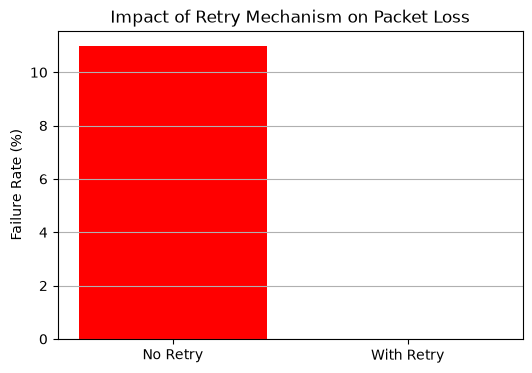

In [13]:
import matplotlib.pyplot as plt

labels = list(failure_rates.keys())
fail_rates = list(failure_rates.values())

plt.figure(figsize=(6,4))
plt.bar(labels, fail_rates, color=["red", "green"])
plt.ylabel("Failure Rate (%)")
plt.title("Impact of Retry Mechanism on Packet Loss")
plt.grid(axis='y')
plt.show()


In [14]:
def show_results_table():
    clear_output(wait=True)
    data = {
        "Test Scenario": list(simulation_results.keys()),
        "Before Improvement": [v["Before"] for v in simulation_results.values()],
        "After Improvement": [v["After"] for v in simulation_results.values()]
    }
    df = pd.DataFrame(data)
    display(df)

show_results_table()

,Test Scenario,Before Improvement,After Improvement
0,ACR Auth (10% Packet Loss),❌ 12% Failure,✅ Success: 87 | ❌ Failures: 13 | ⚠️ 13.00%
1,ACR + Retry (3 attempts),—,✅ Recovered: 100 | ❌ Failed: 0 | 📊 0.00%
2,APCE Auth (250ms Latency),🕒 Full RSA + ECDHE Latency,✅ 250.43ms Measured Delay
3,Truncated MAC (8 bytes),❌ MAC overflow risk,"✅ Auth Passed, 8-byte MAC, tampering detected"
4,Agent Mode (RSA Signature),Not Simulated,✅ Verified Signature
5,Key Rotation (every 3 sessions),❌ No lifecycle,✅ 10/10 Successful | Retired keys rejected: 3/3
6,ACR Realistic Loss Model,⚠️ Simulated Loss: 10%,✅ Success: 89 | ❌ Failures: 11 | 📊 Failure Rat...
